# E-commerce Sales Analysis — Olist (Brazil, 2016–2018)

**Goal:** understand what drives revenue and customer satisfaction for Olist, a Brazilian marketplace,
and turn the findings into actionable recommendations and a Power BI dashboard.

**Data:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) —
~99k orders, 9 relational tables. Cleaned into a star schema by `src/prepare_data.py`.

**Business questions**
1. How fast is the business growing, and are there seasonal peaks?
2. Which product categories drive revenue?
3. Does delivery performance affect customer reviews?
4. Where are the customers, and which regions are under-served by logistics?
5. Do customers come back? Which segments hold the most value?
6. When and how do customers pay / shop?

**Definitions**
- *Revenue* = sum of item `price` for orders not `canceled`/`unavailable` (freight excluded), in BRL.
- *AOV* = average `payment_value` per order (includes freight).
- *Late* = delivered after the estimated delivery date shown to the customer.
- Trend analysis uses **Jan 2017 – Aug 2018**; 2016 and Sep–Oct 2018 contain only a handful of orders.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

orders = pd.read_csv(DATA / "fact_orders.csv", parse_dates=["order_date", "order_purchase_timestamp"])
items = pd.read_csv(DATA / "fact_order_items.csv", parse_dates=["order_date"])
products = pd.read_csv(DATA / "dim_product.csv")
customers = pd.read_csv(DATA / "dim_customer.csv")
rfm = pd.read_csv(DATA / "customer_rfm.csv")

# Chart style: one accent colour, grey for context, light grid.
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b4b2a9"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 10, "axes.axisbelow": True,
})
brl = mtick.FuncFormatter(lambda x, _: f"R${x/1e6:.1f}M" if x >= 1e6 else f"R${x/1e3:.0f}K")

rev_orders = orders[orders["is_revenue_order"]]
print(f"{len(orders):,} orders | {len(items):,} items | {orders.customer_unique_id.nunique():,} customers")
print("Date range:", orders.order_date.min().date(), "→", orders.order_date.max().date())

99,441 orders | 112,650 items | 96,096 customers
Date range: 2016-09-04 → 2018-10-17


## 0. Data quality checks

In [2]:
print("Order status:"); print(orders["order_status"].value_counts().to_string(), "\n")
print("Missing values (fact_orders):")
print(orders.isna().sum()[lambda s: s > 0].to_string(), "\n")
print("Products without category:", (products["category"] == "Unknown").sum())
print("Orders per month outside the analysis window:")
o = orders.set_index("order_date").resample("MS").size()
print(o[(o.index < "2017-01-01") | (o.index > "2018-08-31")].to_string())

Order status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2 

Missing values (fact_orders):
item_count            775
seller_count          775
product_value         775
freight_value         775
payment_value           1
main_payment_type       1
max_installments        1
review_score          768
delivery_days        2971
days_late            2971
is_late              2971 

Products without category: 610
Orders per month outside the analysis window:


order_date
2016-09-01      4
2016-10-01    324
2016-11-01      0
2016-12-01      1
2018-09-01     16
2018-10-01      4


**Notes**
- 97% of orders are `delivered`; `canceled` + `unavailable` (~1.2%) are excluded from revenue.
- Missing delivery dates belong to orders that were never delivered — expected, not an error.
- 610 products have no category → labelled `Unknown` instead of being dropped (their sales are still real).
- 2016 and Sep–Oct 2018 are partial periods, so they are excluded from trend and growth comparisons.

## 1. Headline KPIs

In [3]:
kpi = pd.Series({
    "Revenue (BRL)": rev_orders["product_value"].sum(),
    "Orders": len(rev_orders),
    "Customers": rev_orders["customer_unique_id"].nunique(),
    "Avg order value (BRL)": rev_orders["payment_value"].mean(),
    "Avg review score": orders["review_score"].mean(),
    "Late delivery rate": orders["is_late"].mean(),
    "Median delivery days": orders["delivery_days"].median(),
})
kpi.to_frame("value").style.format("{:,.2f}")

,value
Revenue (BRL),"13,494,400.74"
Orders,"98,199.00"
Customers,"94,983.00"
Avg order value (BRL),160.27
Avg review score,4.09
Late delivery rate,0.07
Median delivery days,10.20


## 2. Growth & seasonality

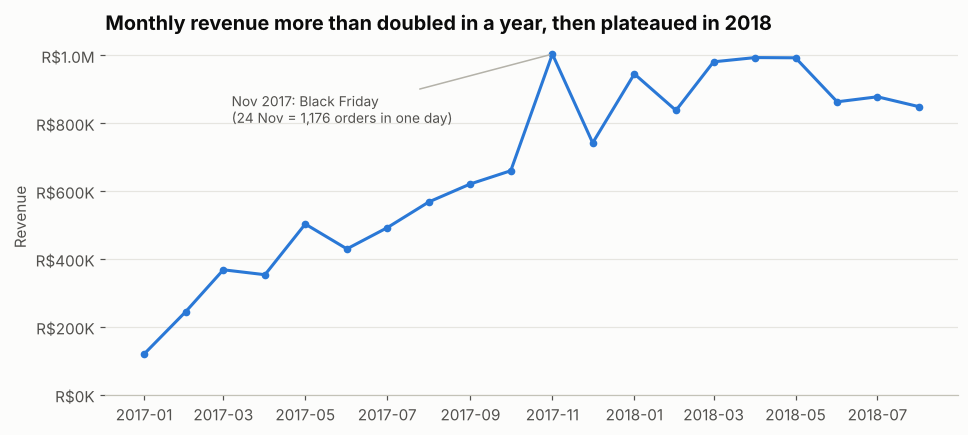

,revenue,orders,aov
order_date,,,
2017,3080850.8,22562.0,158.5
2018,7341037.4,53530.0,160.6
growth %,138.3,137.3,1.3


In [4]:
win = rev_orders[(rev_orders.order_date >= "2017-01-01") & (rev_orders.order_date <= "2018-08-31")]
monthly = win.set_index("order_date").resample("MS").agg(revenue=("product_value", "sum"), orders=("order_id", "count"))

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.index, monthly["revenue"], color=BLUE, lw=2, marker="o", ms=4)
peak = monthly["revenue"].idxmax()
ax.annotate("Nov 2017: Black Friday\n(24 Nov = 1,176 orders in one day)",
            xy=(peak, monthly.loc[peak, "revenue"]), xytext=(-210, -45), textcoords="offset points",
            color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=GREY))
ax.yaxis.set_major_formatter(brl)
ax.set_ylim(0)
ax.set_title("Monthly revenue more than doubled in a year, then plateaued in 2018")
ax.set_xlabel(""); ax.set_ylabel("Revenue")
fig.savefig(FIG / "01_monthly_revenue.png"); plt.show()

yoy = win[win.order_date.dt.month <= 8].groupby(win.order_date.dt.year).agg(
    revenue=("product_value", "sum"), orders=("order_id", "count"), aov=("payment_value", "mean"))
yoy.loc["growth %"] = (yoy.iloc[1] / yoy.iloc[0] - 1) * 100
yoy.round(1)

In [5]:
daily = orders.groupby("order_date").size().sort_values(ascending=False).head(5)
daily.rename("orders").to_frame()

,orders
order_date,
2017-11-24,1176
2017-11-25,499
2017-11-27,403
2017-11-26,391
2017-11-28,380


**Findings**
- Jan–Aug 2018 revenue was **R$7.34M vs R$3.08M** in the same period of 2017 (**+138%**), driven by order volume
  (+137%) — AOV was flat (~R$160). Growth came from *more customers*, not bigger baskets.
- **Black Friday (24 Nov 2017)** produced 1,176 orders in a single day, ~5× a normal day, and made November the
  record month.
- From Jan 2018 revenue **plateaued at ~R$0.85–1.0M/month** — growth momentum slowed.

## 3. Which categories drive revenue?

18 of 74 categories generate 80% of revenue


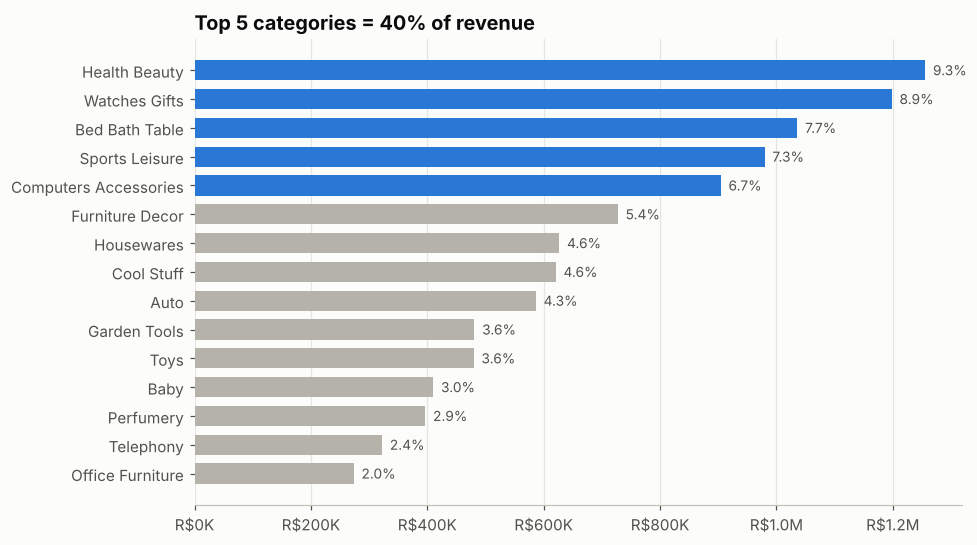

,revenue,items,avg_price,share,cum_share
category,,,,,
Health Beauty,"1,255,695",9634,130.34,9.3%,9.3%
Watches Gifts,"1,198,185",5970,200.70,8.9%,18.2%
Bed Bath Table,"1,035,964",11097,93.36,7.7%,25.9%
Sports Leisure,"979,741",8590,114.06,7.3%,33.1%
Computers Accessories,"904,322",7781,116.22,6.7%,39.8%
Furniture Decor,"727,465",8298,87.67,5.4%,45.2%
Housewares,"626,826",6915,90.65,4.6%,49.9%
Cool Stuff,"620,770",3779,164.27,4.6%,54.5%
Auto,"586,586",4204,139.53,4.3%,58.8%


In [6]:
cat = (items[items.is_revenue_order].merge(products[["product_id", "category"]], on="product_id")
       .groupby("category").agg(revenue=("price", "sum"), items=("price", "size"), avg_price=("price", "mean"))
       .sort_values("revenue", ascending=False))
cat["share"] = cat["revenue"] / cat["revenue"].sum()
cat["cum_share"] = cat["share"].cumsum()
n80 = int((cat["cum_share"] < 0.8).sum() + 1)
print(f"{n80} of {len(cat)} categories generate 80% of revenue")

top = cat.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [BLUE if i >= len(top) - 5 else GREY for i in range(len(top))]
ax.barh(top.index, top["revenue"], color=colors, height=0.7)
for y, (v, s) in enumerate(zip(top["revenue"], top["share"])):
    ax.text(v, y, f"  {s:.1%}", va="center", color=INK2, fontsize=9)
ax.xaxis.set_major_formatter(brl); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title(f"Top 5 categories = {cat['share'].head(5).sum():.0%} of revenue")
fig.savefig(FIG / "02_top_categories.png"); plt.show()
cat.head(10).style.format({"revenue": "{:,.0f}", "avg_price": "{:,.2f}", "share": "{:.1%}", "cum_share": "{:.1%}"})

**Findings**
- Revenue is spread widely: **18 of 74 categories** make up 80% of revenue. No single category dominates (top = 9%).
- **Health & Beauty, Watches & Gifts, Bed Bath & Table, Sports & Leisure, Computer Accessories** are the top 5 (~40%).
- *Watches & Gifts* sells far fewer items than *Bed Bath & Table* but earns nearly as much — high ticket price
  (avg R$201 vs R$93). Two different strategies: volume vs. margin.

## 4. Does late delivery hurt reviews?

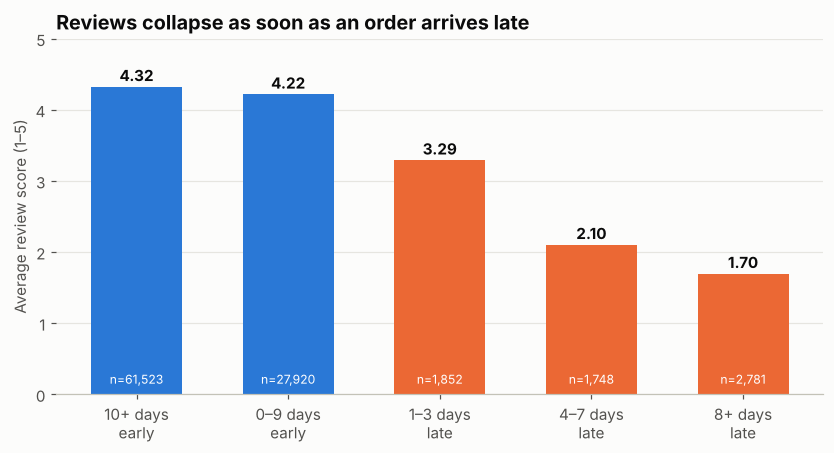

,orders,avg_review,negative_pct
is_late,,,
On time,89443,4.29,9.27
Late,6381,2.27,62.42


,orders,avg_review,negative
bucket,,,
10+ days\nearly,61523,4.323,0.089
0–9 days\nearly,27920,4.217,0.101
1–3 days\nlate,1852,3.291,0.321
4–7 days\nlate,1748,2.103,0.677
8+ days\nlate,2781,1.696,0.793


In [7]:
d = orders[orders.is_delivered & orders.review_score.notna()].copy()
bins = [-np.inf, -10, 0, 3, 7, np.inf]
labels = ["10+ days\nearly", "0–9 days\nearly", "1–3 days\nlate", "4–7 days\nlate", "8+ days\nlate"]
d["bucket"] = pd.cut(d["days_late"], bins=bins, labels=labels)
b = d.groupby("bucket", observed=True).agg(orders=("order_id", "count"), avg_review=("review_score", "mean"),
                                           negative=("review_score", lambda s: (s <= 2).mean()))

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(b.index, b["avg_review"], color=[BLUE, BLUE, ORANGE, ORANGE, ORANGE], width=0.6)
for r, v, n in zip(bars, b["avg_review"], b["orders"]):
    ax.text(r.get_x() + r.get_width() / 2, v + 0.08, f"{v:.2f}", ha="center", fontweight="bold")
    ax.text(r.get_x() + r.get_width() / 2, 0.15, f"n={n:,}", ha="center", color="white", fontsize=8)
ax.set_ylim(0, 5); ax.set_ylabel("Average review score (1–5)")
ax.set_title("Reviews collapse as soon as an order arrives late")
fig.savefig(FIG / "03_delivery_vs_review.png"); plt.show()

late = d.groupby("is_late").agg(orders=("order_id", "count"), avg_review=("review_score", "mean"),
                                negative_pct=("review_score", lambda s: (s <= 2).mean() * 100))
late.index = late.index.map({0: "On time", 1: "Late"})
display(late.round(2)); b.round(3)

**Findings — the most important insight of this analysis**
- Late orders average **2.27 stars vs 4.29** for on-time orders; **62% of late orders get a 1–2 star review**
  (vs 9% on time).
- The damage is immediate and grows with delay: 1–3 days late → 3.29, 8+ days late → 1.70.
- Only 6.8% of orders are late, yet they produce a disproportionate share of negative reviews.
  Fixing logistics is the highest-leverage lever for satisfaction.
- Olist's estimates are very conservative (most orders arrive 10+ days early) — a buffer that keeps
  the late rate low but may discourage purchases by showing long delivery times.

## 5. Geography & logistics

Top 3 states (SP, RJ, MG) = 66.5% of orders


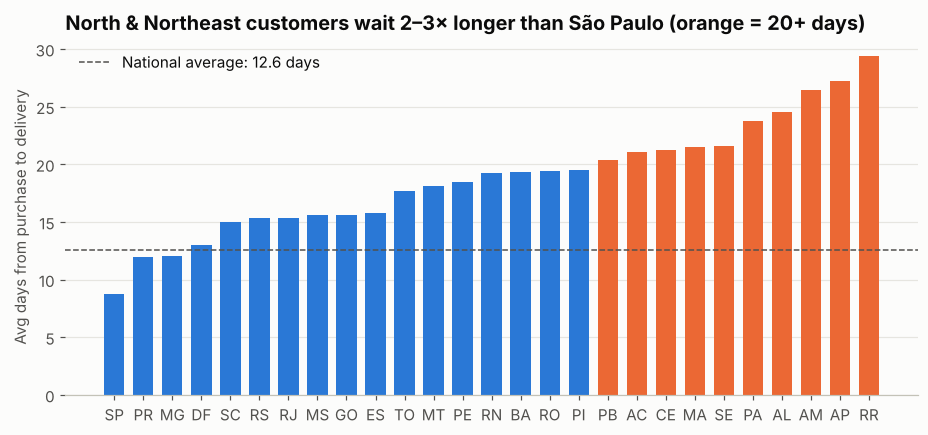

,orders,revenue,freight,order_share,freight_pct_of_price
customer_region,,,,,
Southeast,67338,"8,823,763","1,337,673",68.6%,15.2%
South,13994,"1,936,953","341,293",14.3%,17.6%
Northeast,9305,"1,538,276","334,371",9.5%,21.7%
Central-West,5727,"861,474","151,840",5.8%,17.6%
North,1835,"333,933","75,949",1.9%,22.7%


,customer_state,customer_region,orders,revenue,delivery_days,late_rate,freight,review,order_share,freight_pct
25,SP,Southeast,41122,5164565.11,8.763,0.045,714463.19,4.211,0.419,0.138
18,RJ,Southeast,12702,1811913.20,15.308,0.121,304089.02,3.905,0.129,0.168
10,MG,Southeast,11495,1573663.11,12.009,0.046,269517.20,4.164,0.117,0.171
22,RS,South,5413,742447.88,15.303,0.061,134698.18,4.154,0.055,0.181
17,PR,South,4978,675828.30,11.993,0.040,117178.86,4.211,0.051,0.173
23,SC,South,3603,518677.27,14.951,0.082,89415.70,4.100,0.037,0.172
4,BA,Northeast,3344,507188.84,19.333,0.122,99801.88,3.884,0.034,0.197
6,DF,Central-West,2120,300751.65,12.952,0.056,50437.92,4.090,0.022,0.168
7,ES,Southeast,2019,273622.03,15.796,0.107,49603.20,4.053,0.021,0.181
8,GO,Central-West,1996,287620.46,15.613,0.065,52589.53,4.070,0.020,0.183


In [8]:
geo = (rev_orders.merge(customers[["customer_unique_id", "customer_state", "customer_region"]], on="customer_unique_id")
       .groupby(["customer_state", "customer_region"])
       .agg(orders=("order_id", "count"), revenue=("product_value", "sum"),
            delivery_days=("delivery_days", "mean"), late_rate=("is_late", "mean"),
            freight=("freight_value", "sum"), review=("review_score", "mean"))
       .reset_index().sort_values("orders", ascending=False))
geo["order_share"] = geo["orders"] / geo["orders"].sum()
geo["freight_pct"] = geo["freight"] / geo["revenue"]
print(f"Top 3 states (SP, RJ, MG) = {geo.order_share.head(3).sum():.1%} of orders")

g = geo.sort_values("delivery_days")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(g["customer_state"], g["delivery_days"], color=[ORANGE if v >= 20 else BLUE for v in g["delivery_days"]], width=0.7)
ax.axhline(orders["delivery_days"].mean(), color=INK2, lw=1, ls="--",
           label=f"National average: {orders['delivery_days'].mean():.1f} days")
ax.legend(frameon=False, loc="upper left")
ax.set_ylabel("Avg days from purchase to delivery")
ax.set_title("North & Northeast customers wait 2–3× longer than São Paulo (orange = 20+ days)")
fig.savefig(FIG / "04_delivery_by_state.png"); plt.show()

region = geo.groupby("customer_region").agg(orders=("orders", "sum"), revenue=("revenue", "sum"), freight=("freight", "sum"))
region["order_share"] = region["orders"] / region["orders"].sum()
region["freight_pct_of_price"] = region["freight"] / region["revenue"]
display(region.sort_values("orders", ascending=False).style.format({"revenue": "{:,.0f}", "freight": "{:,.0f}", "order_share": "{:.1%}", "freight_pct_of_price": "{:.1%}"}))
geo.head(10).round(3)

**Findings**
- Demand is concentrated in the Southeast: **SP + RJ + MG = 66% of orders**; São Paulo alone is 42%.
- São Paulo gets orders in **8.8 days** on average; states in the North/Northeast (RR, AP, AM, AL, PA) wait **24–29 days**.
- Freight is a much heavier burden outside the Southeast (≈14% of item price in SP vs 20–28% in the North/Northeast),
  which likely suppresses demand there.
- RJ is an outlier: a big market (13% of orders) with a **12% late rate** — almost 3× SP — and a lower review (3.91).

## 6. Customer retention & RFM segments

Repeat customers: 3.0% of 94,983 customers


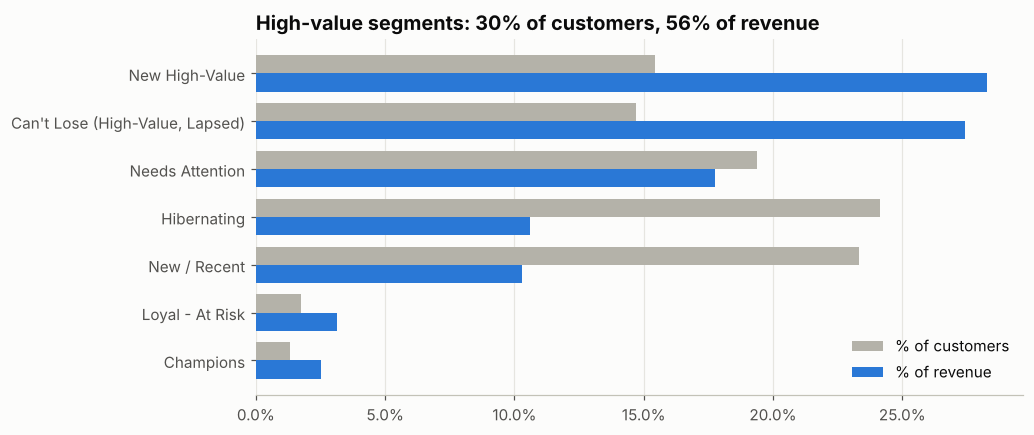

,customers,revenue,recency,customer_share,revenue_share
segment,,,,,
New High-Value,14676,"4,447,766",97,15.5%,28.3%
"Can't Lose (High-Value, Lapsed)",13961,"4,317,849",400,14.7%,27.4%
Needs Attention,18393,"2,795,414",226,19.4%,17.8%
Hibernating,22925,"1,668,757",402,24.1%,10.6%
New / Recent,22141,"1,618,052",95,23.3%,10.3%
Loyal - At Risk,1646,"491,305",327,1.7%,3.1%
Champions,1241,"399,080",94,1.3%,2.5%


In [9]:
print(f"Repeat customers: {(rfm.frequency > 1).mean():.1%} of {len(rfm):,} customers")
seg = rfm.groupby("segment").agg(customers=("customer_unique_id", "count"), revenue=("monetary", "sum"),
                                  recency=("recency_days", "mean")).sort_values("revenue")
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()

fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(seg)); h = 0.38
ax.barh(y + h / 2, seg["customer_share"], h, color=GREY, label="% of customers")
ax.barh(y - h / 2, seg["revenue_share"], h, color=BLUE, label="% of revenue")
ax.set_yticks(y, seg.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.legend(frameon=False, loc="lower right")
ax.set_title("High-value segments: 30% of customers, 56% of revenue")
fig.savefig(FIG / "05_rfm_segments.png"); plt.show()
seg.sort_values("revenue", ascending=False).style.format({"revenue": "{:,.0f}", "recency": "{:.0f}", "customer_share": "{:.1%}", "revenue_share": "{:.1%}"})

**Findings**
- **Only 3% of customers ever place a second order.** Olist is almost entirely an acquisition business —
  this is the biggest structural weakness.
- Two high-value groups — *New High-Value* (recent, big spenders) and *Can't Lose* (big spenders who lapsed >1 year ago) —
  are **30% of customers but 56% of revenue**. They are the obvious targets for retention and win-back campaigns.
- Segment rules (R & M quintiles; F by rule because 97% buy once) are in `src/prepare_data.py::build_rfm`.

## 7. How and when do customers buy?

,orders,aov,installments,share
main_payment_type,,,,
credit_card,74112,166.64,3.55,0.75
boleto,19535,144.69,1.00,0.20
voucher,3037,114.94,1.15,0.03
debit_card,1514,140.27,1.00,0.02


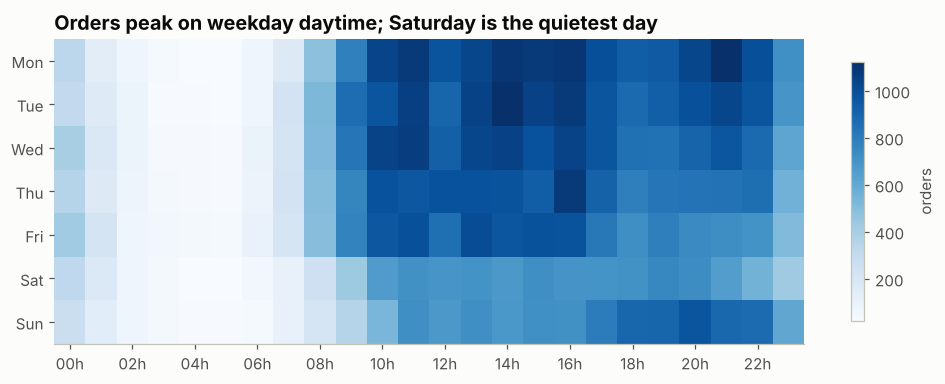

In [10]:
pay = rev_orders.groupby("main_payment_type").agg(orders=("order_id", "count"), aov=("payment_value", "mean"),
                                                  installments=("max_installments", "mean"))
pay["share"] = pay["orders"] / pay["orders"].sum()
display(pay.sort_values("orders", ascending=False).round(2))

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = orders.pivot_table(index="purchase_weekday", columns="purchase_hour", values="order_id", aggfunc="count").reindex(days)
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), [d[:3] for d in days]); ax.set_xticks(range(0, 24, 2), [f"{h:02d}h" for h in range(0, 24, 2)])
ax.grid(False)
fig.colorbar(im, ax=ax, label="orders", shrink=0.85)
ax.set_title("Orders peak on weekday daytime; Saturday is the quietest day")
fig.savefig(FIG / "06_order_heatmap.png"); plt.show()

**Findings**
- **Credit card = 76% of orders**, typically paid in ~3.6 instalments — instalment plans are core to Brazilian e-commerce.
  *Boleto* (bank slip) is still 20%, so it must stay supported.
- Credit-card orders have the highest AOV (R$167 vs R$145 for boleto).
- Shopping happens on **weekdays during working hours (10h–16h) and evenings**; Saturday is the slowest day, while Sunday evening picks up again.
  Campaign emails / push notifications should go out Monday–Tuesday late morning.

## 8. Summary & recommendations

| # | Insight | Recommendation | Expected impact |
|---|---------|----------------|-----------------|
| 1 | Late orders score **2.27★ vs 4.29★**; 62% of them get 1–2★ | Monitor sellers/carriers by late rate; prioritise RJ, BA, CE, MA, AL lanes; proactive delay notifications + coupon | Higher ratings, fewer complaints |
| 2 | Only **3%** of customers buy again | Post-purchase email flow, loyalty points, "buy again" recommendations from the same category | +2pp repeat rate ≈ 1,900 extra orders ≈ +R$0.3M over the same period |
| 3 | 30% of customers (high-value segments) = **56% of revenue** | Win-back campaign for *Can't Lose*; VIP perks for *New High-Value* | Protects the most valuable base |
| 4 | North/Northeast wait **20–29 days**, freight 20–28% of price | Regional fulfilment hub in the Northeast; freight subsidy for selected categories | Unlock under-served markets |
| 5 | Black Friday = **5×** normal daily volume | Plan stock, seller capacity and logistics weeks ahead; replicate with other campaign days | Capture peak demand without delays |
| 6 | Growth plateaued in 2018 at ~R$0.9M/month | Shift focus from acquisition to retention (see #2, #3) | Sustainable growth |

**Limitations:** data covers 2016–2018 only; no cost/margin data, so "revenue" is GMV not profit;
reviews are voluntary, so they may over-represent very happy / very unhappy customers.